# Phase II, Pair 1: question F — neighbouring points

*Can information from neighbouring points change the forecast, in which form must it be given, and what does the model do with it?*

| | |
|---|---|
| Authors | Sandro Müller |
| Status | in progress |
| Phase I result this builds on | Exp 3, 4 and 5 (pressure, a warning flag and neighbours as extra inputs did not improve the drop captured); open question 2 in `phase1-model-behavior/pair-1/experiments/phase2_questions_carlos.md` |

## 1 · Question

Can information from neighbouring points change the forecast, in which form must it be given, and what does the model do with it?

## 2 · Why this question

In Phase I, TiRex-2 forecast the 2 m temperature of each point from its own history only. Giving it more inputs (pressure,
a perfect front flag, neighbouring and upstream points; Exp 3, 4, 5) did not raise the share of the drop it captured
(all about 21 %). We do not know *why*: the model might not see the extra rows at all, it might see them but not use them,
or we might have given them in a form the model cannot use. TiRex-2 accepts neighbours in three different ways (as extra
targets, as past-only covariates, as future-known covariates), and Phase I mostly used past-only channels.

## 3 · Hypothesis and what would count as an answer

**Hypothesis.** Past-only neighbour channels are ignored, as in Phase I. Future covariates and additional targets might
change the forecast: future covariates are read by the reverse (backward-in-time) cell too and reach into the forecast
window, and additional targets are mixed with the point through the variate attention in both directions.

- **If the hypothesis is right, we would see:** for past-only channels a skill gain of about zero, gradients with respect
  to the neighbour channels at the level of a meaningless control channel, and hidden states that barely differ from the
  baseline. For future covariates (shifted, no leakage) and/or extra targets: a skill gain whose confidence interval
  excludes zero, at least for front starts, together with clearly non-zero gradients and hidden-state differences.
- **If it is wrong, we would see:** the same picture for every form: no skill gain, or a gain only in the leakage upper
  bound. If gradients and hidden states move but the skill does not improve, the model *sees* the neighbours but does not
  *use* them for the forecast.

## 4 · Setup

*Imports, paths, model loading.*

### Reading `tirex2.py` first (source checked: `tirex-2==0.3.1`, as pinned in `requirements.txt`, and `main` of `github.com/NX-AI/tirex-2`)

**How the input is grouped.** `PostProcessor.transform_input` packs every `TimeseriesType` of the batch into **one group**:
its target rows first, then its past covariates, then its future covariates. It returns `x` (one row per variate),
`group_vector` (the group id per row) and `target_mask` (True for target rows). `TiRex2._prepare_forward` then sets
`known_covariate_mask = has a value in the last future_len steps & not a target`, so future covariates are "known",
past covariates (NaN in the future part) are not.

**`variate_indices(group_vector, target_mask, known_covariate_mask)`** (in `main`; 0.3.1 computes the same inside the
blocks) returns two index sets, once per forward pass:
- `reverse_idx`: the rows that also go through the **reverse** xLSTM cell of the time mixer, i.e. the known (future)
  covariates (all non-targets if there is no `known_covariate_mask`). Targets and past covariates only run forward in time.
- `attention_idx`: the rows whose group has **more than one row**. Only these rows enter the variate attention;
  a lone univariate series skips it.

**Do several targets exchange information?** Yes. Each `MultivariateBlock` runs (1) the time mixer on every row on its
own, then (2) the `variate_mixer`, an `AttentionBlock` over the rows of each group at every token position. The mask
is `same_group & ~(covariate → target)`: rows of different groups (different samples of the batch) never see each other,
**covariates cannot attend to targets**, but **targets attend to every row of their group, including other targets**.
So rows given as extra targets of the same `TimeseriesType` are mixed with the point in both directions in every block;
they are not just batched. Form (i) can therefore work in principle. Rows given as separate `TimeseriesType`s (as in
`run_forecasts.py`) are only batched and never mix.

Two side effects to keep in mind: each target row is scaled and, if `tta_diff` finds a trend, differenced on its own; and
with `tta_sign_flip` the whole forecast is run a second time on the negated input and averaged.

**How to pass the inputs to `forecast()`.**
`TimeseriesType(target=[n_targets, T], past_covariates=[n_past, T] or None, future_covariates=[n_fut, ≥ T+H] or None)`,
then `model.forecast([ts, ...], prediction_length=H, output_type="numpy")`. Each output is `[n_targets, 9 quantiles, H]`;
row 0 is our point. Future covariates longer than `T+H` are cut.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tirex2 import TimeseriesType, load_model

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = Path(os.environ.get("AIVIS_DATA", ROOT / "data" / "austria_15km"))
CKPT = os.environ.get("TIREX_CKPT", "NX-AI/TiRex-2")  # a local folder works too
DEVICE = os.environ.get("TIREX_DEVICE", "cpu")
RESULTS = ROOT / "data" / "notebooks" / "results" / "06_question_f"
RESULTS.mkdir(parents=True, exist_ok=True)

CONTEXT, HORIZON = 672, 24  # Phase I design: 28 days of history, 24 h forecast
QUANTILES = np.arange(1, 10) / 10
SEED = 0

model = load_model(CKPT, device=DEVICE)  # as in phase1-model-behavior/pair-1/run_forecasts.py
core = model.model  # the TiRex2 backbone
print(
    "input_patch_size",
    core.input_patch_size,
    "| blocks",
    len(core.stack),
    "| context_len",
    core.context_len,
    "| future_len",
    core.future_len,
    "| tta_sign_flip",
    core.tta_sign_flip,
    "| tta_diff",
    core.tta_diff,
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

input_patch_size 32 | blocks 12 | context_len 2048 | future_len 320 | tta_sign_flip False | tta_diff True


## 5 · Data

Austria 15 km dataset (378 points, hourly, 2025-10-01 → 2026-10-01). Same design as Phase I: 672 h context, 24 h horizon,
the context filled exactly as in `run_forecasts.py`; forecasts are scored against the observed (unfilled) temperature.

**Cases.** The start times are taken from the Phase I file `tirex2_forecasts.npz`, so the baseline can be checked against
Phase I: `N_GRID` grid starts spread over the year (seeded) and **all** front starts (front-12, front-6). The points are
`N_POINTS` interior points (all four lattice neighbours present), spread over Austria by farthest-point sampling. Every
form runs on exactly these start × point cases, not on the full 336 × 378 (Phase I needed about 75 minutes for that).

**Neighbours** (from `points_with_labels.csv`, Austria Lambert x/y in metres):
- *nearest*: the 4 lattice neighbours within 16 km (N, S, E, W);
- *upwind*: per case, from the mean wind (`UU`, `VV`) at the point over the last 6 h of the context, the up to 3 nearest
  points within 60 km that lie within ±35° of the direction the wind comes from. The travel time is distance / wind speed.
  With wind below 1 m/s, or no point in the sector, the 3 nearest points are used and the case is flagged.

Sample size: about 12 grid + 30 front starts × 10 points ≈ 400 cases per form. Gains are reported with a bootstrap over
start times (cases of one start are not independent).

In [2]:
N_GRID, N_POINTS = 12, 10
K_NEAR, NEAR_KM = 4, 16
K_UP, UP_KM, UP_HALF_ANGLE, WIND_HOURS, MIN_WIND = 3, 60, 35, 6, 1.0

pts = pd.read_csv(DATA / "points_with_labels.csv").set_index("point_id")
grid = pd.read_parquet(DATA / "grid_long.parquet")
cols = [c for c in ["T2M", "UU", "VV"] if c in grid.columns]
wide = {c: grid.pivot(index="time", columns="point_id", values=c) for c in cols}
OBS = wide["T2M"]  # observed, with gaps, for scoring
T = OBS.interpolate(limit_area="inside").ffill().bfill()  # filled, as in run_forecasts.py, for the context
times, pids = T.index, T.columns.to_numpy()
pts = pts.loc[pids]
SER = T.to_numpy(np.float32).copy()  # [time, point]
HAS_WIND = {"UU", "VV"} <= set(cols)
if HAS_WIND:
    UU = wide["UU"].reindex(times).interpolate(limit_area="inside").ffill().bfill().to_numpy(np.float32)
    VV = wide["VV"].reindex(times).interpolate(limit_area="inside").ffill().bfill().to_numpy(np.float32)
else:
    print("No UU/VV in grid_long.parquet: upwind falls back to a westerly wind (from 270°)")

XY = pts[["x", "y"]].to_numpy(float) / 1000  # km
DIST = np.linalg.norm(XY[:, None] - XY[None], axis=-1)
col = {p: j for j, p in enumerate(pids)}


def nearest(j, k=K_NEAR, max_km=NEAR_KM):
    order = [i for i in np.argsort(DIST[j]) if i != j and DIST[j, i] <= max_km]
    return order[:k]


def upwind(j, i):
    """Upwind neighbours of point j for the forecast starting at time index i (only context hours are used)."""
    if HAS_WIND:
        u, v = UU[i - WIND_HOURS : i, j].mean(), VV[i - WIND_HOURS : i, j].mean()
    else:
        u, v = 3.0, 0.0
    speed = float(np.hypot(u, v))
    if speed >= MIN_WIND:
        come_from = -np.array([u, v]) / speed  # direction the air comes from
        d = XY - XY[j]
        dn = np.linalg.norm(d, axis=1)
        cosang = (d @ come_from) / np.maximum(dn, 1e-9)
        ok = (dn > 0) & (dn <= UP_KM) & (cosang >= np.cos(np.deg2rad(UP_HALF_ANGLE)))
        cand = [int(c) for c in np.where(ok)[0][np.argsort(dn[ok])]][:K_UP]
        if cand:
            travel = [int(np.ceil(DIST[j, c] / (speed * 3.6))) for c in cand]
            return cand, travel, speed, False
    cand = nearest(j, K_UP, UP_KM)
    return cand, [HORIZON] * len(cand), speed, True


# start times from the Phase I forecasts
P1 = np.load(DATA / "tirex2_forecasts.npz", allow_pickle=True)
p1_col = {p: k for k, p in enumerate(P1["pids"])}
rng = np.random.default_rng(SEED)
grid_k = np.where(P1["tags"] == "grid")[0]
grid_k = np.sort(rng.choice(grid_k, size=min(N_GRID, len(grid_k)), replace=False))
front_k = np.where(np.char.startswith(P1["tags"].astype(str), "front"))[0]
starts = [(int(P1["origin_idx"][k]), str(P1["tags"][k]), int(k)) for k in np.r_[grid_k, front_k]]
starts = [s for s in starts if s[0] >= CONTEXT and s[0] + HORIZON <= len(times)]

# interior points, spread out by farthest-point sampling
interior = [j for j in range(len(pids)) if len(nearest(j)) == K_NEAR]
chosen = [interior[int(rng.integers(len(interior)))]]
while len(chosen) < min(N_POINTS, len(interior)):
    dmin = DIST[np.ix_(interior, chosen)].min(axis=1)
    chosen.append(interior[int(np.argmax(dmin))])

cases = []
for i, tag, k in starts:
    for j in chosen:
        up, travel, speed, fallback = upwind(j, i)
        cases.append(
            {
                "i": i,
                "tag": tag,
                "p1_k": k,
                "j": j,
                "pid": pids[j],
                "near": nearest(j),
                "up": up,
                "travel": travel,
                "wind": speed,
                "up_fallback": fallback,
                "front": tag.startswith("front"),
            }
        )
cases = pd.DataFrame(cases)
print(
    f"{len(starts)} starts ({len(grid_k)} grid, {len(starts) - len(grid_k)} front) x {len(chosen)} points = {len(cases)} cases;"
    f" upwind fallback in {cases.up_fallback.mean():.0%}; median travel time {np.median(np.concatenate(cases.travel.to_numpy())):.0f} h"
)

42 starts (12 grid, 30 front) x 10 points = 420 cases; upwind fallback in 37%; median travel time 6 h


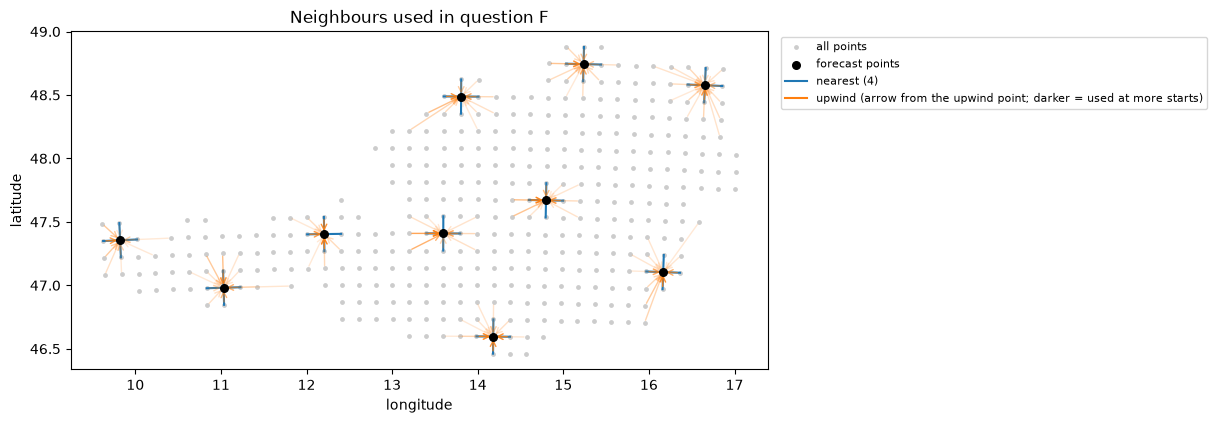

In [3]:
# map of the neighbours used
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(pts.lon, pts.lat, s=6, c="0.8", label="all points")
lonlat = pts[["lon", "lat"]].to_numpy()
up_count = {}
for _, c in cases.iterrows():
    for u in c.up:
        up_count[(c.j, u)] = up_count.get((c.j, u), 0) + 1
n_starts = len(starts)
for (j, u), n in up_count.items():
    ax.annotate(
        "",
        xy=lonlat[j],
        xytext=lonlat[u],
        arrowprops={"arrowstyle": "->", "color": "tab:orange", "alpha": 0.15 + 0.85 * n / n_starts, "lw": 1},
    )
for j in chosen:
    for nb in nearest(j):
        ax.plot(*lonlat[[j, nb]].T, color="tab:blue", lw=1.5)
ax.scatter(*lonlat[chosen].T, s=30, c="k", zorder=3, label="forecast points")
ax.plot([], [], color="tab:blue", label="nearest (4)")
ax.plot([], [], color="tab:orange", label="upwind (arrow from the upwind point; darker = used at more starts)")
ax.set(xlabel="longitude", ylabel="latitude", title="Neighbours used in question F")
ax.set_aspect(1 / np.cos(np.deg2rad(lonlat[:, 1].mean())))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.savefig(RESULTS / "map_neighbours.png", dpi=150, bbox_inches="tight")

### Forms of neighbour information

All forms run on the same cases; only the `TimeseriesType` changes. The context of the point is always the 672 h before
the forecast start `i`; an input series "shifted by `s`" has the value of the source at hour `τ - s` at hour `τ`.

| Form | Input | Uses data after `i`? |
|---|---|---|
| `base` | the point alone | no |
| `p_past` | the 4 nearest neighbours as past-only covariates (the Phase I way) | no |
| `i_targets` | the 4 nearest neighbours as extra rows in `target` (forecast of row 0 is scored) | no |
| `ii_future` | the upwind points as future covariates, shifted by `max(travel time, 24 h)` | no (shift ≥ horizon) |
| `iii_features` | neighbour mean, spatial gradient (x, y), upwind difference as future covariates, shifted like `ii` | no |
| `leak_upper` | the upwind points unshifted, as future covariates: their real future values | **yes, upper bound only** |

The shift must be at least the horizon: with `s ≥ 24`, the newest value used at the last forecast hour `i + 23` is the
source at `i - 1`. Hours before the start of the record are NaN (the model masks them).

In [4]:
def shifted(src, i, s, length):
    """Hours [i - CONTEXT, i - CONTEXT + length) of src (1-D over the time axis), shifted by s hours; NaN before the record."""
    idx = np.arange(i - CONTEXT, i - CONTEXT + length) - s
    out = np.full(length, np.nan, np.float32)
    ok = (idx >= 0) & (idx < len(src))
    out[ok] = src[idx[ok]]
    if s >= HORIZON:  # leakage rule: nothing at or after the forecast start
        assert idx.max() <= i - 1
    return out


def features(c):
    """Engineered neighbour features over the whole time axis: mean, gradient x/y (°C per 100 km), upwind difference."""
    j, near, up = c["j"], list(c["near"]), list(c["up"])
    mean = SER[:, near].mean(axis=1)
    nbrs = [j, *near]
    A = np.c_[np.ones(len(nbrs)), XY[nbrs] - XY[j]]  # plane fit T = a + gx*dx + gy*dy
    coef = np.linalg.lstsq(A, SER[:, nbrs].T, rcond=None)[0]
    gx, gy = coef[1] * 100, coef[2] * 100
    updiff = SER[:, up].mean(axis=1) - SER[:, j]
    return np.stack([mean, gx, gy, updiff]).astype(np.float32)


def build(c, form, null_offset=0):
    """TimeseriesType of one case in one form. null_offset != 0 takes the neighbour series from another date (control)."""
    i, j = int(c["i"]), int(c["j"])
    tgt = torch.from_numpy(SER[i - CONTEXT : i, j][None].copy())
    o = null_offset
    near, up = list(c["near"]), list(c["up"])
    shift_up = [max(t, HORIZON) for t in c["travel"]]
    if form == "base":
        return TimeseriesType(target=tgt, past_covariates=None, future_covariates=None)
    if form == "p_past":
        pc = np.stack([shifted(SER[:, n], i, o, CONTEXT) for n in near])
        return TimeseriesType(target=tgt, past_covariates=torch.from_numpy(pc), future_covariates=None)
    if form == "i_targets":
        rows = [SER[i - CONTEXT : i, j]] + [shifted(SER[:, n], i, o, CONTEXT) for n in near]
        return TimeseriesType(target=torch.from_numpy(np.stack(rows)), past_covariates=None, future_covariates=None)
    if form == "ii_future":
        fc = np.stack([shifted(SER[:, u], i, s + o, CONTEXT + HORIZON) for u, s in zip(up, shift_up)])
        return TimeseriesType(target=tgt, past_covariates=None, future_covariates=torch.from_numpy(fc))
    if form == "iii_features":
        f = features(c)
        s_up = max(shift_up)
        fc = np.stack([shifted(f[k], i, (HORIZON if k < 3 else s_up) + o, CONTEXT + HORIZON) for k in range(4)])
        return TimeseriesType(target=tgt, past_covariates=None, future_covariates=torch.from_numpy(fc))
    if form == "leak_upper":
        fc = np.stack([shifted(SER[:, u], i, 0, CONTEXT + HORIZON) for u in up])
        return TimeseriesType(target=tgt, past_covariates=None, future_covariates=torch.from_numpy(fc))
    raise ValueError(form)


FORMS = ["base", "p_past", "i_targets", "ii_future", "iii_features", "leak_upper"]
NEIGHBOUR_FORMS = FORMS[1:]


def run_form(form, cases, batch_size=64):
    path = RESULTS / f"preds_{form}.npy"
    if path.exists():
        p = np.load(path)
        if len(p) == len(cases):
            return p
    t0 = time.time()
    batch = [build(c, form) for c in cases.to_dict("records")]
    out = model.forecast(batch, prediction_length=HORIZON, output_type="numpy", batch_size=batch_size)
    p = np.stack([f[0] for f in out]).astype(np.float32)  # row 0 = the point; [case, 9, 24]
    np.save(path, p)
    print(f"{form}: {len(cases)} cases in {time.time() - t0:.0f}s")
    return p


PRED = {f: run_form(f, cases) for f in FORMS}

## 6 · Technique 1 — skill gain

Per case: MAE of the median over the 24 forecast hours against the observed temperature, and the coverage of the
0.1–0.9 band (nominal 80 %). Gain = MAE(base) − MAE(form), so **positive = better than the point alone**. Mean gain per
form, split by normal (grid) and front starts, with a 95 % bootstrap interval over start times.

*What it shows:* whether a form improves the forecast on average. *What it cannot show:* whether the model reads the
neighbours at all; no gain can mean "ignored" or "seen but not used" (Technique 2 separates the two).

In [5]:
obs = np.stack([OBS.to_numpy(np.float32)[c.i : c.i + HORIZON, c.j] for c in cases.itertuples()])  # [case, 24]


def mae(p):
    return np.nanmean(np.abs(p[:, 4] - obs), axis=1)


def coverage(p):
    inside = (obs >= p[:, 0]) & (obs <= p[:, 8])
    return np.nanmean(np.where(np.isnan(obs), np.nan, inside.astype(float)), axis=1)


def boot_ci(values, groups, n=2000, seed=SEED):
    """95 % interval of the mean, resampling whole start times."""
    r = np.random.default_rng(seed)
    ug = np.unique(groups)
    by = [values[groups == g] for g in ug]
    means = [np.nanmean(np.concatenate([by[k] for k in r.integers(len(ug), size=len(ug))])) for _ in range(n)]
    return np.nanpercentile(means, [2.5, 97.5])


score = pd.DataFrame({"case": np.arange(len(cases)), "start": cases.i, "front": cases.front})
for f in FORMS:
    score[f"mae_{f}"], score[f"cov_{f}"] = mae(PRED[f]), coverage(PRED[f])

rows = []
for f in FORMS:
    for label, sel in [
        ("all", np.ones(len(cases), bool)),
        ("normal", ~cases.front.to_numpy()),
        ("front", cases.front.to_numpy()),
    ]:
        g = (score["mae_base"] - score[f"mae_{f}"]).to_numpy()[sel]
        lo, hi = boot_ci(g, score.start.to_numpy()[sel]) if f != "base" else (0.0, 0.0)
        rows.append(
            {
                "form": f,
                "starts": label,
                "n": int(sel.sum()),
                "mae": score[f"mae_{f}"][sel].mean(),
                "gain": np.nanmean(g),
                "gain_lo": lo,
                "gain_hi": hi,
                "coverage": score[f"cov_{f}"][sel].mean(),
            }
        )
gain = pd.DataFrame(rows)
gain.to_csv(RESULTS / "skill_gain.csv", index=False)
gain.round(3)

,form,starts,n,mae,gain,gain_lo,gain_hi,coverage
0,base,all,420,2.720,0.000,0.000,0.000,0.656
1,base,normal,120,1.676,0.000,0.000,0.000,0.815
2,base,front,300,3.138,0.000,0.000,0.000,0.593
3,p_past,all,420,2.756,-0.035,-0.061,-0.009,0.639
4,p_past,normal,120,1.686,-0.009,-0.054,0.026,0.802
5,p_past,front,300,3.183,-0.046,-0.076,-0.013,0.574
6,i_targets,all,420,2.755,-0.035,-0.060,-0.009,0.639
7,i_targets,normal,120,1.685,-0.009,-0.053,0.026,0.802
8,i_targets,front,300,3.183,-0.045,-0.075,-0.012,0.575
9,ii_future,all,420,2.829,-0.108,-0.231,0.005,0.548


## 7 · Technique 2 — does anything move?

Two internal measures, on a subset of cases (all front cases of `GRAD_POINTS` points plus as many grid cases):

- **Gradient** of the median forecast at hour `FORECAST_HOUR` with respect to every input row. Sensitivity of a form =
  summed |gradient| over the neighbour rows / summed |gradient| over the point's own context. For future covariates the
  context part and the forecast-window part are reported separately.
- **Hidden-state distance** between the run with neighbours and the baseline, per block: ‖h_form − h_base‖ / ‖h_base‖
  over all tokens of the point's row.

**Control.** The same forms with the neighbour series taken from 30 days earlier (real temperatures, wrong dates: `null`).
A form whose numbers are at the level of its control is ignored in practice.

**Reading:** gradients ≈ control and states unchanged → the model ignores that form. Gradients and states clearly above
the control but no skill gain → the model sees the information but does not use it.

The two functions below are the Phase II helpers (`hidden_states`, `gradient`) widened to take a full `TimeseriesType`,
so that gradients with respect to covariate and extra-target rows are available. The gradient uses a NaN-safe copy of
the scaler (see section 12 for why). Swap in the shared helpers from
`p2/pair1-model-helpers` once they accept covariates; the check in section 9 compares them with `model.forecast`.

In [6]:
import types

FORECAST_HOUR, GRAD_POINTS, NULL_OFFSET = 12, 4, 30 * 24


def _predict(ts_list, grad):
    """TiRex2.predict without the no_grad decorator (same sign-flip TTA)."""
    with torch.set_grad_enabled(grad):
        f = core._predict(ts_list, HORIZON, tta_diff=core.tta_diff, preserve_grad=grad)
        if core.tta_sign_flip:
            fl = core._predict(
                [core._sign_flip(t) for t in ts_list], HORIZON, tta_diff=core.tta_diff, preserve_grad=grad
            )
            comp = core._complement_indices().to(fl[0].device)
            f = [(a - b.index_select(1, comp)) / 2 for a, b in zip(f, fl)]
    return f


def hidden_states(ts):
    """Output of every block for the rows of one TimeseriesType, first (unflipped) pass: [blocks, rows, tokens, dim]."""
    out = []
    hooks = [b.register_forward_hook(lambda m, a, o: out.append(o[0].detach().cpu())) for b in core.stack]
    try:
        _predict([ts], grad=False)
    finally:
        for h in hooks:
            h.remove()
    return torch.stack(out[: len(core.stack)]).numpy()


def _nan_safe_scale(self, x):
    """Same values as Scaler.scale, but NaN padding never enters an operation that has a gradient.
    (With the original, arcsinh and the division backpropagate NaN from the padding into loc/scale and so into
    every input hour.)"""
    valid = ~torch.isnan(x)
    x0 = torch.where(valid, x, torch.zeros_like(x))
    n = valid.sum(-1, keepdim=True)
    loc = torch.where(n > 0, x0.sum(-1, keepdim=True) / n.clamp_min(1), torch.zeros_like(n, dtype=x.dtype))
    var = torch.where(valid, (x0 - loc) ** 2, torch.zeros_like(x)).sum(-1, keepdim=True) / n.clamp_min(1)
    scale = torch.where(n > 0, var.clamp_min(self.eps**2).sqrt(), torch.ones_like(var))
    is_binary = None
    if self.binaryaware:
        is_binary = ((x0 == 0.0) | (x0 == 1.0) | ~valid).all(dim=-1, keepdim=True)
        loc = torch.where(is_binary, torch.zeros_like(loc), loc)
        scale = torch.where(is_binary, torch.ones_like(scale), scale)
    scaled = (x0 - loc) / scale
    if self.use_arcsinh:
        scaled = (
            torch.where(is_binary, scaled, torch.arcsinh(scaled)) if is_binary is not None else torch.arcsinh(scaled)
        )
    return torch.where(valid, scaled, torch.full_like(scaled, float("nan"))), (loc, scale, is_binary)


class nan_safe_scaler:
    def __enter__(self):
        core.scaler.scale = types.MethodType(_nan_safe_scale, core.scaler)

    def __exit__(self, *exc):
        del core.scaler.scale  # back to the class method


def gradient(ts, forecast_hour=FORECAST_HOUR):
    """d median(point, forecast_hour) / d input, for target, past and future covariate rows."""
    leaves = {
        k: (getattr(ts, k).clone().requires_grad_(True) if getattr(ts, k) is not None else None)
        for k in ("target", "past_covariates", "future_covariates")
    }
    with nan_safe_scaler():
        f = _predict([TimeseriesType(**leaves)], grad=True)[0]
    f[0, 4, forecast_hour].backward()
    return {k: (v.grad.numpy().copy() if v is not None else None) for k, v in leaves.items()}


def sensitivity(g):
    own = np.nansum(np.abs(g["target"][0]))
    r = {"own": own}
    if g["target"].shape[0] > 1:
        r["nbr_ctx"] = np.nansum(np.abs(g["target"][1:])) / own
    if g["past_covariates"] is not None:
        r["nbr_ctx"] = np.nansum(np.abs(g["past_covariates"])) / own
    if g["future_covariates"] is not None:
        fc = np.abs(g["future_covariates"])
        r["nbr_ctx"], r["nbr_future"] = np.nansum(fc[:, :CONTEXT]) / own, np.nansum(fc[:, CONTEXT:]) / own
    return r


def null_build(c, form):
    return build(c, form, null_offset=NULL_OFFSET)  # 30 days earlier; NaN before the record


gsub = cases[cases.j.isin(chosen[:GRAD_POINTS])]
gsub = pd.concat([gsub[gsub.front], gsub[~gsub.front].head(int(gsub.front.sum()))])
T2_FORMS = ["p_past", "i_targets", "ii_future", "iii_features", "leak_upper"]
rows = []
t0 = time.time()
for c in gsub.to_dict("records"):
    h_base = hidden_states(build(c, "base"))[:, 0]
    for form in T2_FORMS:
        for kind, maker in [("real", build), ("null", null_build)]:
            if kind == "null" and form == "leak_upper":
                continue
            ts = maker(c, form)
            h = hidden_states(ts)[:, 0]
            dist = np.linalg.norm((h - h_base).reshape(len(h), -1), axis=1) / np.linalg.norm(
                h_base.reshape(len(h), -1), axis=1
            )
            s = sensitivity(gradient(ts))
            rows.append(
                {
                    "i": c["i"],
                    "j": c["j"],
                    "front": c["front"],
                    "form": form,
                    "kind": kind,
                    **s,
                    **{f"h{b}": d for b, d in enumerate(dist)},
                }
            )
moved = pd.DataFrame(rows)
moved.to_csv(RESULTS / "sensitivity.csv", index=False)
print(f"{len(gsub)} cases in {time.time() - t0:.0f}s")
hcols = [c for c in moved.columns if c.startswith("h") and c[1:].isdigit()]
moved.groupby(["form", "kind"])[["nbr_ctx", "nbr_future", *hcols]].mean().round(4)

168 cases in 3220s


nbr_ctx  nbr_future      h0      h1      h2      h3  \
form         kind                                                        
i_targets    null   0.2297         NaN  0.0129  0.0159  0.0255  0.0290   
             real   0.2836         NaN  0.0129  0.0161  0.0261  0.0298   
ii_future    null   0.3751      0.0571  0.0144  0.0187  0.0299  0.0435   
             real   0.5497      0.0731  0.0145  0.0188  0.0300  0.0448   
iii_features null   0.5778      0.0569  0.0149  0.0204  0.0336  0.0482   
             real   0.8902      0.0894  0.0150  0.0205  0.0339  0.0494   
leak_upper   real   1.0494      0.3537  0.0145  0.0188  0.0301  0.0452   
p_past       null   0.2295         NaN  0.0129  0.0159  0.0255  0.0290   
             real   0.2827         NaN  0.0129  0.0161  0.0261  0.0298   

                       h4      h5      h6      h7      h8      h9     h10  \
form         kind                                                           
i_targets    null  0.0519  0.0548  0.0619  0.0654  0.0744  0.1062  0.0908   
             real  0.0529  0.0562  0.0646  0.0692  0.0788  0.1140  0.0974   
ii_future    null  0.0819  0.1061  0.1382  0.1904  0.2258  0.2367  0.2026   
             real  0.0855  0.1159  0.1600  0.2204  0.2721  0.2992  0.2530   
iii_features null  0.0876  0.1040  0.1336  0.1800  0.2146  0.2200  0.1912   
             real  0.0909  0.1144  0.1580  0.2188  0.2669  0.2874  0.2463   
leak_upper   real  0.1121  0.1578  0.2411  0.2866  0.3642  0.3994  0.3660   
p_past       null  0.0519  0.0548  0.0619  0.0654  0.0743  0.1061  0.0908   
             real  0.0529  0.0562  0.0646  0.0692  0.0788  0.1140  0.0974   

                      h11  
form         kind          
i_targets    null  0.0155  
             real  0.0163  
ii_future    null  0.0423  
             real  0.0555  
iii_features null  0.0378  
             real  0.0525  
leak_upper   real  0.0928  
p_past       null  0.0156  
             real  0.0163

### Figures

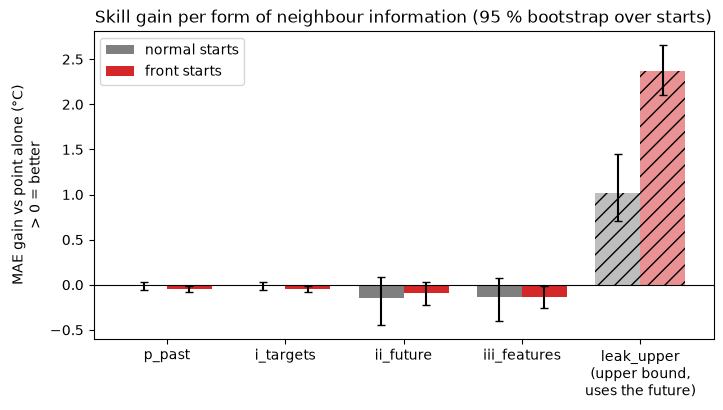

In [7]:
# skill gain per form, normal vs front starts
fig, ax = plt.subplots(figsize=(8, 4))
g = gain[(gain.form != "base") & (gain.starts != "all")]
forms = [f for f in FORMS if f != "base"]
for k, (label, color) in enumerate([("normal", "tab:gray"), ("front", "tab:red")]):
    d = g[g.starts == label].set_index("form").loc[forms]
    x = np.arange(len(forms)) + (k - 0.5) * 0.38
    bars = ax.bar(
        x, d.gain, 0.38, yerr=[d.gain - d.gain_lo, d.gain_hi - d.gain], color=color, label=f"{label} starts", capsize=3
    )
    bars[forms.index("leak_upper")].set_hatch("//")
    bars[forms.index("leak_upper")].set_alpha(0.5)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(
    range(len(forms)), [f if f != "leak_upper" else "leak_upper\n(upper bound,\nuses the future)" for f in forms]
)
ax.set(
    ylabel="MAE gain vs point alone (°C)\n> 0 = better",
    title="Skill gain per form of neighbour information (95 % bootstrap over starts)",
)
ax.legend()
fig.savefig(RESULTS / "skill_gain.png", dpi=150, bbox_inches="tight")

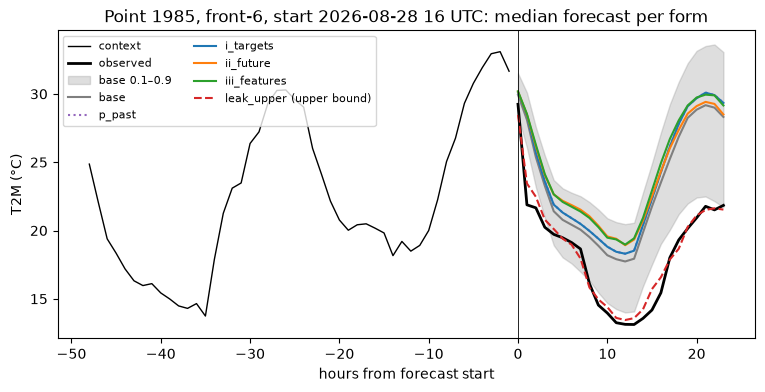

In [8]:
# forecast lines with and without neighbours, for the front case with the largest observed fall after the start
fc = cases[cases.front].copy()
fc["fall"] = [SER[c.i - 1, c.j] - np.nanmin(obs[k]) for k, c in fc.iterrows()]
k = int(fc["fall"].idxmax())
c = cases.loc[k]
hours = np.arange(-48, HORIZON)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hours[:48], SER[c.i - 48 : c.i, c.j], color="k", lw=1, label="context")
ax.plot(hours[48:], obs[k], color="k", lw=2, label="observed")
ax.fill_between(hours[48:], PRED["base"][k, 0], PRED["base"][k, 8], color="tab:gray", alpha=0.25, label="base 0.1–0.9")
styles = {
    "base": ("tab:gray", "-"),
    "p_past": ("tab:purple", ":"),
    "i_targets": ("tab:blue", "-"),
    "ii_future": ("tab:orange", "-"),
    "iii_features": ("tab:green", "-"),
    "leak_upper": ("tab:red", "--"),
}
for f in FORMS:
    col_, ls = styles[f]
    ax.plot(hours[48:], PRED[f][k, 4], color=col_, ls=ls, label=f + (" (upper bound)" if f == "leak_upper" else ""))
ax.axvline(0, color="k", lw=0.6)
ax.set(
    xlabel="hours from forecast start",
    ylabel="T2M (°C)",
    title=f"Point {c.pid}, {c.tag}, start {times[c.i]:%Y-%m-%d %H} UTC: median forecast per form",
)
ax.legend(fontsize=8, ncol=2)
fig.savefig(RESULTS / "front_case_lines.png", dpi=150, bbox_inches="tight")

## 8 · Comparing the techniques

*Do they agree? Where do they differ?* Per form: skill gain (Technique 1) next to sensitivity and hidden-state distance
relative to the control (Technique 2). Four outcomes:

| Gain | Moves (above control) | Reading |
|---|---|---|
| ≈ 0 | no | ignored |
| ≈ 0 | yes | seen but not used |
| > 0 | yes | used |
| > 0 | no | suspicious: check the leakage rule and the cases |

*To fill after the run: which row each form falls into.*

In [9]:
ratio = (
    moved[moved.kind == "real"].groupby("form")[["nbr_ctx", "nbr_future", hcols[-1]]].mean()
    / moved[moved.kind == "null"].groupby("form")[["nbr_ctx", "nbr_future", hcols[-1]]].mean()
)
cmp = (
    gain[gain.starts == "all"]
    .set_index("form")
    .loc[T2_FORMS, ["gain", "gain_lo", "gain_hi"]]
    .join(moved[moved.kind == "real"].groupby("form")[["nbr_ctx", "nbr_future", hcols[-1]]].mean())
    .join(ratio.add_suffix("_vs_null"))
)
cmp.round(4)

,gain,gain_lo,gain_hi,nbr_ctx,nbr_future,h11,nbr_ctx_vs_null,nbr_future_vs_null,h11_vs_null
form,,,,,,,,,
p_past,-0.0352,-0.0607,-0.0094,0.2827,NaN,0.0163,1.2320,NaN,1.0476
i_targets,-0.0348,-0.0601,-0.0087,0.2836,NaN,0.0163,1.2347,NaN,1.0500
ii_future,-0.1083,-0.2310,0.0054,0.5497,0.0731,0.0555,1.4654,1.2798,1.3116
iii_features,-0.1322,-0.2373,-0.0240,0.8902,0.0894,0.0525,1.5408,1.5725,1.3912
leak_upper,1.9868,1.6997,2.2825,1.0494,0.3537,0.0928,NaN,NaN,NaN


## 9 · Checks

*Does the result hold on other dates, other points, other groups? What did we try to break it with?*

1. **Leakage rule:** every non-leak form must be unchanged when everything after the forecast start is overwritten.
2. **Baseline match:** `base` must reproduce the Phase I forecasts in `tirex2_forecasts.npz` (stored as float16).
3. **Same cases:** every form was scored on the same start × point cases, in the same order.
4. **Helpers vs `model.forecast`:** the gradient path (`_predict`, also with the NaN-safe scaler) gives the same
   quantiles as `model.forecast`, and the gradients are finite.
5. **Split by groups:** gain per point and per front/normal start, to see whether one point or one front carries the mean.

In [10]:
# 1 leakage: corrupt all data from the forecast start on and rebuild
c = cases.iloc[0].to_dict()
keep = SER.copy()
ref = {f: build(c, f) for f in FORMS}
SER[c["i"] :] = 999.0
for f in FORMS:
    t = build(c, f)
    same = all(
        np.array_equal(getattr(t, a).numpy(), getattr(ref[f], a).numpy(), equal_nan=True)
        for a in ("target", "past_covariates", "future_covariates")
        if getattr(t, a) is not None
    )
    print(
        f"leakage check {f:13s}: {'unchanged' if same else 'CHANGED'}"
        + ("  (expected: upper bound)" if f == "leak_upper" else "")
    )
    assert same or f == "leak_upper"
SER[:] = keep

# 2 baseline match against Phase I
preds = P1["preds"]  # read the array from the file once, not once per case
p1 = np.stack([preds[c.p1_k, p1_col[c.pid]] for c in cases.itertuples()]).astype(np.float32)
diff = np.abs(PRED["base"] - p1)
print(f"baseline vs Phase I: max |diff| {diff.max():.4f} °C, mean {diff.mean():.5f} °C")
assert diff.max() < 0.05, "baseline does not reproduce Phase I"

# 3 same cases for every form
assert all(len(PRED[f]) == len(cases) for f in FORMS) and set(score.columns) >= {f"mae_{f}" for f in FORMS}

# 4 gradient path == model.forecast
ts = build(c, "i_targets")
a = _predict([ts], grad=False)[0].numpy()
b = model.forecast([ts], prediction_length=HORIZON, output_type="numpy")[0]
with nan_safe_scaler():
    a2 = _predict([ts], grad=False)[0].numpy()
print(
    f"_predict vs forecast: shapes {a.shape} {b.shape}, max |diff| {np.abs(a - b).max():.2e};"
    f" with the NaN-safe scaler used for gradients: {np.abs(a2 - b).max():.2e}"
)
assert a.shape == b.shape and np.allclose(a, b, atol=1e-4) and np.allclose(a2, b, atol=1e-3)
g = gradient(build(c, "ii_future"))
assert all(
    np.isfinite(v[~np.isnan(getattr(build(c, "ii_future"), k).numpy())]).all() for k, v in g.items() if v is not None
)

# 5 gain per point and start type
per_point = score.assign(pid=cases.pid).groupby(["pid", "front"])[[f"mae_{f}" for f in FORMS]].mean()
(per_point[[f"mae_{f}" for f in FORMS[1:]]].rsub(per_point["mae_base"], axis=0)).round(3)

leakage check base         : unchanged
leakage check p_past       : unchanged
leakage check i_targets    : unchanged
leakage check ii_future    : unchanged
leakage check iii_features : unchanged
leakage check leak_upper   : CHANGED  (expected: upper bound)


baseline vs Phase I: max |diff| 0.0156 °C, mean 0.00235 °C


_predict vs forecast: shapes (5, 9, 24) (5, 9, 24), max |diff| 0.00e+00; with the NaN-safe scaler used for gradients: 0.00e+00


mae_p_past  mae_i_targets  mae_ii_future  mae_iii_features  \
pid  front                                                               
63   False       0.011          0.012         -0.169            -0.101   
     True       -0.018         -0.017          0.002            -0.032   
555  False       0.055          0.057         -0.121            -0.091   
     True       -0.075         -0.075         -0.166            -0.153   
928  False      -0.001         -0.000         -0.246            -0.201   
     True       -0.054         -0.054         -0.204            -0.240   
1455 False      -0.019         -0.018          0.309             0.260   
     True        0.001          0.001         -0.167            -0.192   
1487 False      -0.003         -0.002         -0.051            -0.034   
     True       -0.062         -0.060         -0.124            -0.114   
1508 False       0.002          0.003         -0.209            -0.297   
     True       -0.043         -0.043         -0.118            -0.133   
1985 False       0.017          0.017         -0.214            -0.139   
     True       -0.070         -0.069         -0.139            -0.225   
3022 False      -0.050         -0.051         -0.144            -0.135   
     True       -0.013         -0.013         -0.099            -0.163   
3198 False      -0.078         -0.079         -0.255            -0.253   
     True       -0.051         -0.050          0.007            -0.024   
3281 False      -0.029         -0.029         -0.319            -0.355   
     True       -0.070         -0.070          0.058            -0.035   

            mae_leak_upper  
pid  front                  
63   False           0.827  
     True            1.539  
555  False           1.026  
     True            2.278  
928  False           1.346  
     True            2.227  
1455 False           0.456  
     True            1.878  
1487 False           0.862  
     True            2.779  
1508 False           0.650  
     True            2.482  
1985 False           1.053  
     True            2.763  
3022 False           1.200  
     True            2.625  
3198 False           1.335  
     True            2.583  
3281 False           1.421  
     True            2.592

## 10 · Figure decisions

| Figure | Keep / change / drop | Why |
|---|---|---|
| Map of the neighbours used (`map_neighbours.png`) | keep | shows which points fed each form; upwind arrows show how the wind picked them |
| Skill gain per form (`skill_gain.png`) | keep | main Technique 1 result; leak bar hatched and labelled as an upper bound so it cannot be read as a result |
| Forecast lines, one front case (`front_case_lines.png`) | keep | makes the gain (or its absence) concrete for one case; one case only, so not evidence on its own |
| Sensitivity / hidden-state table | *decide after the run* | a bar chart per block if the forms differ by block |

## 11 · What it means

*Answer to the question, in plain words. What is still open?*

*To fill after the run.* Points to answer:
- Which form, if any, gets past the "ignores neighbours" behaviour from Phase I (gain above zero without leakage)?
- Is the effect limited to front starts?
- How far below the leakage upper bound is the best real form, i.e. how much of the neighbours' value is lost by the
  shift of at least 24 h?
- For forms that move the hidden states but bring no gain: is that "seen but not used"?

## 12 · What did not work

*Dead ends and why. They are part of the record.*

- **Past-only channels (`p_past`).** Phase I gave neighbours as past covariates (Exp 3, 4). From the source, past
  covariates run only forward in time (they are not in `reverse_idx`) and end at the forecast start; the target can
  still attend to them. *To fill: what the run shows (gain, gradients and states vs the control).*
- **Upstream as a covariate without a shift.** Only possible as the leakage upper bound: with a travel time of a few hours,
  an honest future covariate must be shifted by at least the 24 h horizon, which throws away most of the advance warning.
- **Plain backpropagation through `predict`.** Every input gradient came out NaN: the context is padded with NaN up to
  `context_len + future_len`, and the backward pass of the scaler's division and `arcsinh` multiplies by those NaN values,
  which reach the mean and scale and from there every hour. Fixed with a NaN-safe copy of `Scaler.scale` used only for the
  gradients (same forward values, checked in section 9).
- **Neighbours as separate batch entries** (as in `run_forecasts.py`): from the source they are in different groups and
  never mix, so this was not run.
- *To fill: anything else that failed during the run.*